# Laptop Consumer Preferences: A Conjoint Analysis

In [ ]:
import pandas as pd
import numpy as np
import warnings
import matplotlib.pyplot as plt
from helper.functions import *
import seaborn as sns
from scipy.stats import spearmanr

warnings.filterwarnings("ignore")
pd.set_option('display.max_rows', None)

In [2]:
df =pd.read_excel("survey_data.xlsx", header =[0,1])



In [3]:
first_header = df.columns.get_level_values(0)

data= df.copy()
data.columns = first_header

In [4]:
cols = [f"Q5_{i}" for i in range(1, 11)]

cleaned_df = data[["ResponseId"] + cols].copy()

In [5]:
ranking_cols = [f"Q5_{i}" for i in range(1, 11)]

long_data = cleaned_df.melt(
    id_vars="ResponseId",
    value_vars=ranking_cols,
    var_name="QuestionId",
    value_name="Rank"
)

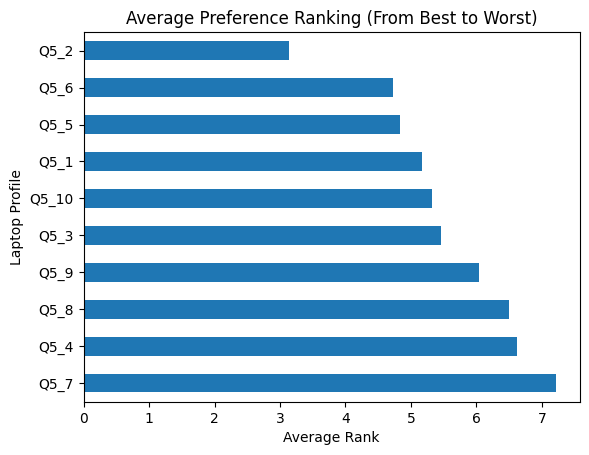

In [6]:
avg_rank = long_data.groupby("QuestionId")["Rank"].mean()

avg_rank.sort_values(ascending=False).plot(kind="barh")

plt.xlabel("Average Rank")
plt.ylabel("Laptop Profile")
plt.title("Average Preference Ranking (From Best to Worst)")
plt.show()

In [7]:
attributes = df[["ResponseId"] + cols].copy()


In [8]:
attr = design_matrix(attributes)


In [9]:
attr = attr.rename(columns={"Profile": "QuestionId"})


In [10]:
conjoint_data = pd.DataFrame(long_data.merge(
    attr,
    on="QuestionId",
    how="left"
))

In [11]:
utility_df = calculate_utilities(conjoint_data)
importance_df = calculate_importance(utility_df)

<function matplotlib.pyplot.tight_layout(*, pad: 'float' = 1.08, h_pad: 'float | None' = None, w_pad: 'float | None' = None, rect: 'tuple[float, float, float, float] | None' = None) -> 'None'>

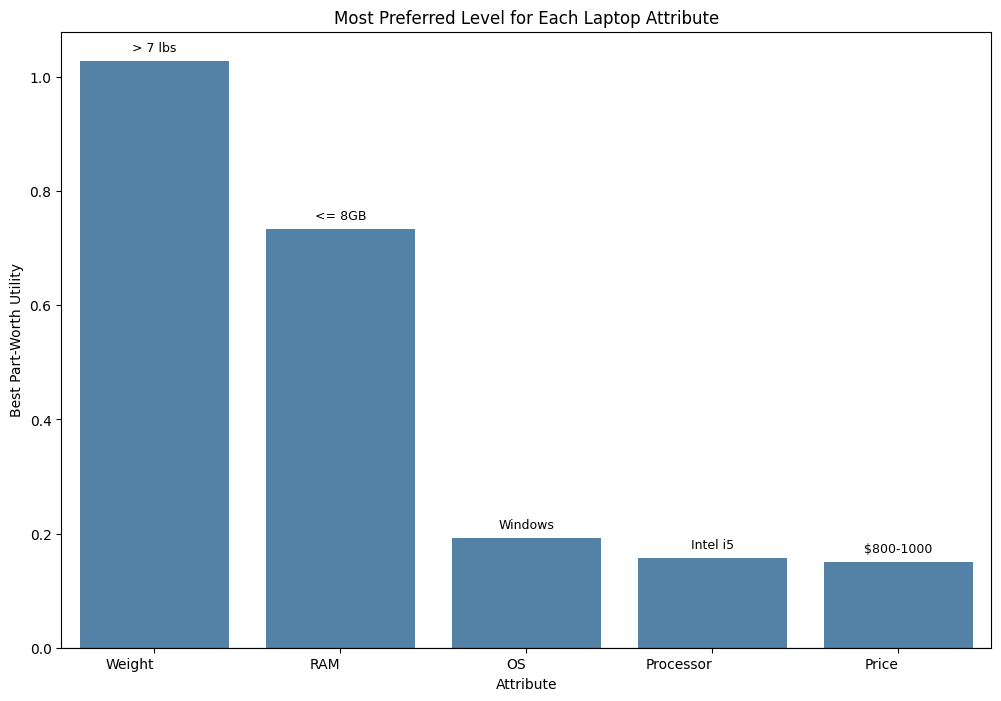

In [12]:


best_levels = utility_df.loc[
    utility_df.groupby("Attribute")["Utility"].idxmax()
].copy()

best_levels = best_levels.sort_values("Utility", ascending=False)

plt.figure(figsize=(12, 8))

ax = sns.barplot(
    data=best_levels,
    x="Attribute",
    y="Utility",
    color="steelblue"
)

# Label each bar with its best level
for bar, (_, row) in zip(ax.patches, best_levels.iterrows()):
    ax.annotate(
        str(row["Level"]),
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        xytext=(0, 5),
        textcoords="offset points",
        ha="center",
        va="bottom",
        fontsize=9
    )

plt.axhline(0, color="black", linewidth=0.8)
plt.title("Most Preferred Level for Each Laptop Attribute")
plt.xlabel("Attribute")
plt.ylabel("Best Part-Worth Utility")
plt.xticks( ha="right")
plt.tight_layout

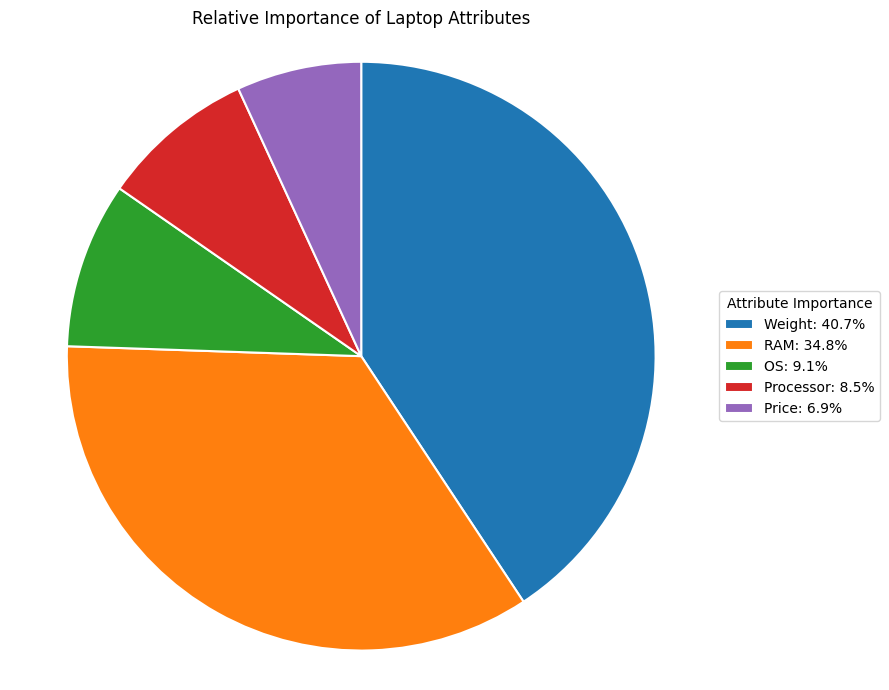

In [13]:

fig, ax = plt.subplots(figsize=(9, 7))

wedges, _ = ax.pie(
    importance_df["Importance (%)"],
    startangle=90,
    counterclock=False,
    wedgeprops={"edgecolor": "white", "linewidth": 1.5}
)

legend_labels = [
    f"{attribute}: {importance:.1f}%"
    for attribute, importance in zip(
        importance_df["Attribute"],
        importance_df["Importance (%)"]
    )
]

ax.legend(
    wedges,
    legend_labels,
    title="Attribute Importance",
    loc="center left",
    bbox_to_anchor=(1, 0.5)
)

# Save the chart
plt.savefig(
    "./img/laptop_attribute_importance.png",
    dpi=300,
    bbox_inches="tight"
)


ax.set_title("Relative Importance of Laptop Attributes")
ax.axis("equal")
plt.tight_layout()
plt.show()

In [14]:


attributes = ["Price", "RAM", "Processor", "Weight", "OS"]
summary_rows = []

for attribute in attributes:
    stats = (
        conjoint_data
        .groupby(attribute)["Rank"]
        .agg(
            Count="count",
            Mean_Rank="mean",
            Median_Rank="median"
        )
        .reset_index()
        .sort_values("Mean_Rank")
    )

    best = stats.iloc[0]
    total_count = stats["Count"].sum()

    summary_rows.append({
        "Attribute": attribute,
        "Importance (%)": importance_df.loc[
            importance_df["Attribute"] == attribute,
            "Importance (%)"
        ].iloc[0],
        "Most Preferred Level": best[attribute],
        "Profile share (%)": best["Count"] / total_count * 100,
        "Mean Rank": best["Mean_Rank"].round(2),
        "Median Rank": best["Median_Rank"]
    })

summary_df = (
    pd.DataFrame(summary_rows)
    .sort_values("Importance (%)", ascending=False)
    .reset_index(drop=True)
)

summary_df

,Attribute,Importance (%),Most Preferred Level,Profile share (%),Mean Rank,Median Rank
0,Weight,40.703664,> 7 lbs,30.0,4.67,4.0
1,RAM,34.834891,<= 8GB,50.0,4.99,5.0
2,OS,9.117489,Windows,60.0,5.27,5.0
3,Processor,8.488419,Intel i5,40.0,5.39,5.0
4,Price,6.855538,$500–800,30.0,5.31,5.0


In [ ]:

attributes = ["Price", "RAM", "Processor", "Weight", "OS"]

data = conjoint_data.dropna(
    subset=attributes + ["Rank"]
).copy()

# Rank 1 = best, Rank 10 = worst
data["Preference"] = 11 - data["Rank"]

X = pd.get_dummies(
    data[attributes],
    drop_first=True,
    dtype=float
)

model = LinearRegression()
model.fit(X, data["Preference"])

data["Predicted_Preference"] = model.predict(X)

profile_validation = (
    data.groupby("QuestionId")
    .agg(
        Actual_Mean_Rank=("Rank", "mean"),
        Predicted_Preference=("Predicted_Preference", "mean"),
        Actual_Mean_Preference=("Preference", "mean")
    )
    .reset_index()
    .sort_values("Actual_Mean_Rank")
)

profile_validation

,QuestionId,Actual_Mean_Rank,Predicted_Preference,Actual_Mean_Preference
2,Q5_2,3.132353,7.467262,7.867647
6,Q5_6,4.727941,5.700080,6.272059
5,Q5_5,4.838235,5.532588,6.161765
0,Q5_1,5.161765,5.380653,5.838235
1,Q5_10,5.316176,6.027011,5.683824
3,Q5_3,5.455882,4.743348,5.544118
9,Q5_9,6.044118,5.985443,4.955882
8,Q5_8,6.492647,4.793342,4.507353
4,Q5_4,6.617647,5.469112,4.382353
7,Q5_7,7.213235,3.901160,3.786765


In [ ]:


rho, p_value = spearmanr(
    profile_validation["Actual_Mean_Preference"],
    profile_validation["Predicted_Preference"]
)

print(f"Spearman correlation: {rho:.3f}")
print(f"P-value: {p_value:.4f}")

Spearman correlation: 0.636
P-value: 0.0479


## Conclusion

Weight and RAM are the strongest drivers of laptop preference, together accounting for 75.5% of total attribute importance. Operating system, processor, and price have comparatively limited influence. The conjoint model shows a moderate, statistically significant agreement with respondents' actual rankings (Spearman $\rho$ = 0.636, *p* = 0.0479), suggesting it captures overall preference patterns reasonably well.